In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyodbc
import plotly.express as px
import plotly.graph_objects as go

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
conn = pyodbc.connect("DRIVER={ODBC Driver 17 for SQL Server};"
                      "SERVER=localhost\\SQLEXPRESS01;"
                      "DATABASE=MotoDB;"
                      "Trusted_Connection=yes;")

In [4]:
df = pd.read_sql("SELECT * FROM MotoDB.dbo.VehicleSales", conn)

C:\Users\fares\AppData\Local\Temp\ipykernel_35524\3831369478.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM MotoDB.dbo.VehicleSales", conn)


In [5]:
df.head(10)

,Id,Year,Make,Model,Trim,Body,Transmission,VIN,State,ConditionValue,Odometer,Color,Interior,Seller,MMR,SellingPrice,SaleDate
0,2,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.00,"16,639.00",white,black,kia motors america inc,"20,500.00","21,500.00",2014-12-16 04:30:00
1,3,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.00,"9,393.00",white,beige,kia motors america inc,"20,800.00","21,500.00",2014-12-16 04:30:00
2,4,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.00,"1,331.00",gray,black,financial services remarketing (lease),"31,900.00","30,000.00",2015-01-14 20:30:00
3,5,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.00,"14,282.00",white,black,volvo na rep/world omni,"27,500.00","27,750.00",2015-01-28 20:30:00
4,6,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.00,"2,641.00",gray,black,financial services remarketing (lease),"66,000.00","67,000.00",2014-12-18 04:30:00
5,7,2015,Nissan,Altima,2.5 S,Sedan,automatic,1n4al3ap1fn326013,ca,1.00,"5,554.00",gray,black,enterprise vehicle exchange / tra / rental / t...,"15,350.00","10,900.00",2014-12-30 04:00:00
6,8,2014,BMW,M5,Base,Sedan,automatic,wbsfv9c51ed593089,ca,34.00,"14,943.00",black,black,the hertz corporation,"69,000.00","65,000.00",2014-12-17 04:30:00
7,9,2014,Chevrolet,Cruze,1LT,Sedan,automatic,1g1pc5sb2e7128460,ca,2.00,"28,617.00",black,black,enterprise vehicle exchange / tra / rental / t...,"11,900.00","9,800.00",2014-12-16 05:00:00
8,10,2014,Audi,A4,2.0T Premium Plus quattro,Sedan,automatic,wauffafl3en030343,ca,42.00,"9,557.00",white,black,audi mission viejo,"32,100.00","32,250.00",2014-12-18 04:00:00
9,11,2014,Chevrolet,Camaro,LT,Convertible,automatic,2g1fb3d37e9218789,ca,3.00,"4,809.00",red,black,d/m auto sales inc,"26,300.00","17,500.00",2015-01-19 20:00:00


In [6]:
def summary(df):
    return pd.DataFrame({
        "dtype": df.dtypes,
        "nan_count": df.isna().sum(),
        "nan_percent": df.isna().mean() * 100,
        "unique": df.nunique(),
    })

summary(df)

,dtype,nan_count,nan_percent,unique
Id,int64,0,0.00,558837
Year,int64,0,0.00,34
Make,object,10301,1.84,96
Model,object,10399,1.86,973
Trim,object,10651,1.91,1963
Body,object,13195,2.36,87
Transmission,object,65352,11.69,4
VIN,object,4,0.00,550297
State,object,0,0.00,64
ConditionValue,float64,11820,2.12,41


# what we understand
- no problems of data types
- small percent of nan values in cols [Make, Model, Trim, Body, VIN, ConditionValue, Odometer, Color, Interior, MMR, SellingPrice, SaleDate]
- big problem of nan values in column (Transmission)

# 1. Remove broken rows
- 26 rows are shifted one column to the right ("sedan" ended up in Transmission). Even after shifting them back they have no price or sale date, so they are dropped
- Rows with no selling price, MMR or sale date are dropped too

In [7]:
df = df[df["Transmission"].str.lower() != "sedan"]
df = df.dropna(subset=["SellingPrice", "MMR", "SaleDate"]).reset_index(drop=True)

# 2. Fill Make, Model, Trim
- The first 7 characters of the VIN identify the car, so fill each column with the most common value for that VIN prefix
- Fill any remaining Trim with the most common trim of the same make + model
- Drop the few rows still missing

In [8]:
df["VIN7"] = df["VIN"].str[:7].str.upper()

for col in ["Make", "Model", "Trim"]:
    vin_map = df.dropna(subset=[col]).groupby("VIN7")[col].agg(lambda x: x.mode()[0])
    df[col] = df[col].fillna(df["VIN7"].map(vin_map))

df["Trim"] = df["Trim"].fillna(
    df.groupby(["Make", "Model"])["Trim"].transform(lambda x: x.mode()[0] if x.notna().any() else None)
)

df = df.dropna(subset=["Make", "Model", "Trim"])

# 3. Clean text
- Lowercase so "Ford" / "ford" and "Sedan" / "sedan" become one value
- "—" in Color / Interior means missing

In [9]:
for col in ["Make", "Model", "Trim", "Body"]:
    df[col] = df[col].str.lower().str.strip()

df["Make"] = df["Make"].replace({"gmc truck": "gmc"})
df[["Color", "Interior"]] = df[["Color", "Interior"]].replace("—", np.nan)

# 4. Fill Body and Transmission
One helper for both columns. It goes through the groups from most specific to least specific (for example make + model + trim, then make + model):
- For each group, take the most common value
- Use it only if the group has at least `min_count` cars and that value covers at least `min_conf` of them
- By default groups are built from real values only, so a filled value never affects a later group (tested: more accurate for Body)
- `chained=True` also learns from values filled at earlier levels (tested: fills more Transmission values correctly)

In [10]:
def fill_from_groups(df, target, levels, chained=False):
    known = df.dropna(subset=[target])

    for cols, min_count, min_conf in levels:
        if chained:
            known = df.dropna(subset=[target])

        counts = known[cols + [target]].value_counts().reset_index(name="n")
        counts["total"] = counts.groupby(cols)["n"].transform("sum")
        best = counts.drop_duplicates(subset=cols)
        best = best[(best["total"] >= min_count) & (best["n"] / best["total"] >= min_conf)]

        missing = df[target].isna()
        df.loc[missing, target] = df.loc[missing, cols].merge(best, on=cols, how="left")[target].values
        print(cols, f"{target} missing:", df[target].isna().sum())

In [11]:
df["VIN_PART"] = df["VIN"].str.lower().str[3:8]

fill_from_groups(df, "Body", [
    (["Make", "Model", "Trim"], 2, 0.95),
    (["Make", "VIN_PART"], 2, 1.00),
    (["Make", "Model"], 2, 0.98),
    (["VIN7"], 2, 1.00),
])

df = df.dropna(subset=["Body"]).drop(columns=["VIN7", "VIN_PART"])

['Make', 'Model', 'Trim'] Body missing: 6666
['Make', 'VIN_PART'] Body missing: 3903


['Make', 'Model'] Body missing: 1771
['VIN7'] Body missing: 957


In [12]:
fill_from_groups(df, "Transmission", [
    (["Make", "Model", "Trim", "Year"], 3, 0.95),
    (["Make", "Model", "Trim"], 3, 0.95),
    (["Make", "Model"], 3, 0.95),
], chained=True)

df["Transmission"] = df["Transmission"].fillna("unknown")

['Make', 'Model', 'Trim', 'Year'] Transmission missing: 10619


['Make', 'Model', 'Trim'] Transmission missing: 7840


['Make', 'Model'] Transmission missing: 5941


# 5. Condition, Odometer, Color, Interior
- Condition uses two scales (1–5 and 11–49), so divide values above 5 by 10
- Odometer 999,999 is a placeholder, not a real reading
- Fill Condition and Odometer with the median of the same make + model + year, and drop the few rows still missing
- Fill Color and Interior with "unknown"

In [13]:
df.loc[df["ConditionValue"] > 5, "ConditionValue"] /= 10
df.loc[df["Odometer"] == 999999, "Odometer"] = np.nan

for col in ["ConditionValue", "Odometer"]:
    df[col] = df[col].fillna(df.groupby(["Make", "Model", "Year"])[col].transform("median"))

df = df.dropna(subset=["ConditionValue", "Odometer"])
df[["Color", "Interior"]] = df[["Color", "Interior"]].fillna("unknown")

# 6. Remove price outliers
Keep cars that sold for 0.35–1.69 times their MMR (about the 1st to 99th percentile).

In [14]:
df["price_to_mmr"] = df["SellingPrice"] / df["MMR"]
df = df[df["price_to_mmr"].between(0.35, 1.69)]

summary(df)

,dtype,nan_count,nan_percent,unique
Id,int64,0,0.00,545607
Year,int64,0,0.00,28
Make,object,0,0.00,60
Model,object,0,0.00,818
Trim,object,0,0.00,1805
Body,object,0,0.00,45
Transmission,object,0,0.00,3
VIN,object,0,0.00,537373
State,object,0,0.00,38
ConditionValue,float64,0,0.00,78


# 7. Save cleaned data
Saved next to this notebook, so the EDA (or any other notebook) can load it without the SQL Server connection.

In [15]:
df.to_csv("cleaned_cars.csv", index=False)

df.shape

(545607, 18)

# EDA
- **Univariate:** one column at a time
- **Bivariate:** two columns at a time (each column vs selling price)
- **Multivariate:** three or more columns together

In [16]:
df = df.reset_index(drop=True)
df["car_age"] = (df["SaleDate"].dt.year - df["Year"]).clip(lower=0)

sns.set_theme(style="whitegrid")
BLUE = "#2a78d6"

## A. Univariate analysis

### 1. Summary of numeric columns

In [17]:
df[["SellingPrice", "MMR", "Odometer", "ConditionValue", "car_age"]].describe()

,SellingPrice,MMR,Odometer,ConditionValue,car_age
count,"545,607.00","545,607.00","545,607.00","545,607.00","545,607.00"
mean,"13,863.49","14,012.62","66,660.22",3.44,4.72
std,"9,688.57","9,636.99","50,664.26",0.94,3.81
min,100.00,100.00,1.00,1.00,0.00
25%,"7,300.00","7,525.00","28,104.50",2.70,2.00
50%,"12,300.00","12,450.00","51,158.00",3.60,3.00
75%,"18,400.00","18,500.00","96,916.50",4.20,7.00
max,"183,000.00","182,000.00","959,276.00",5.00,28.00


### 2. Distribution of numeric columns

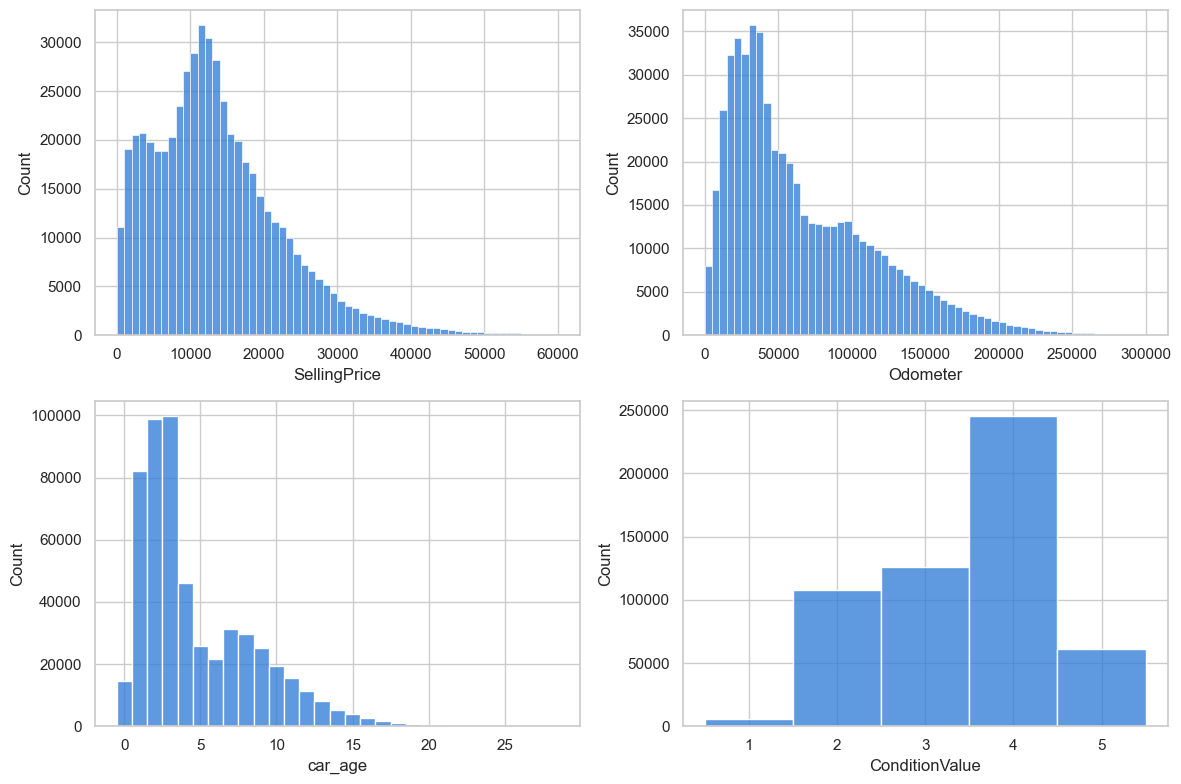

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["SellingPrice"], bins=60, binrange=(0, 60_000), color=BLUE, ax=axes[0, 0])
sns.histplot(df["Odometer"], bins=60, binrange=(0, 300_000), color=BLUE, ax=axes[0, 1])
sns.histplot(df["car_age"], discrete=True, color=BLUE, ax=axes[1, 0])
sns.histplot(df["ConditionValue"].round(), discrete=True, color=BLUE, ax=axes[1, 1])

plt.tight_layout()
plt.show()

### 3. Most common categories

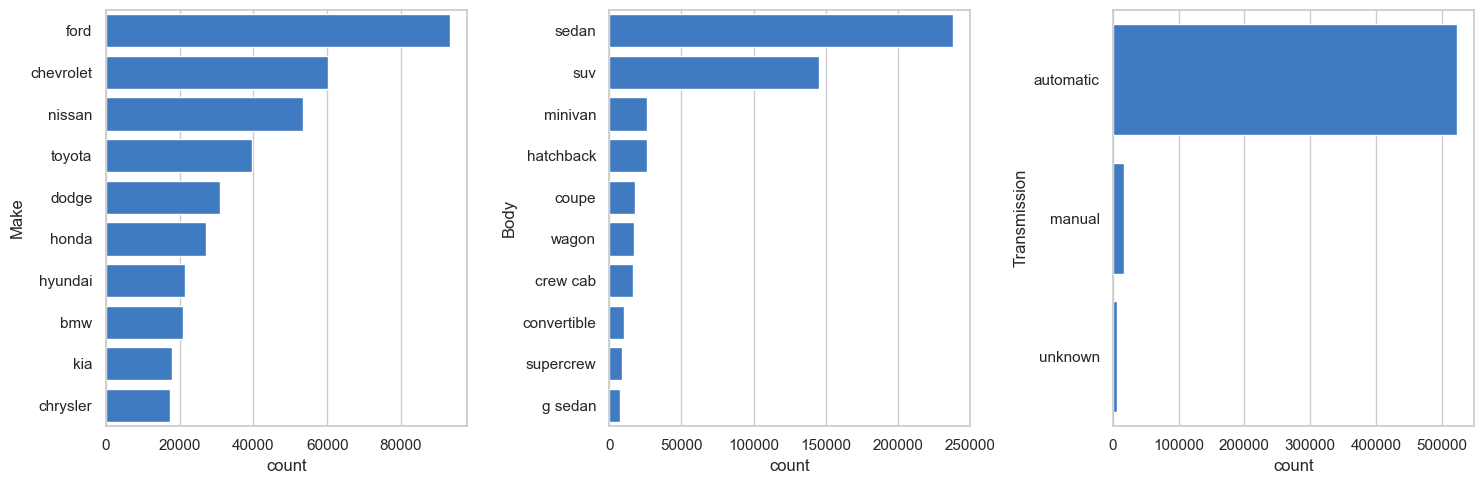

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["Make", "Body", "Transmission"]):
    sns.countplot(data=df, y=col, order=df[col].value_counts().index[:10], color=BLUE, ax=ax)

plt.tight_layout()
plt.show()

## B. Bivariate analysis

### 4. Price vs age, mileage and condition

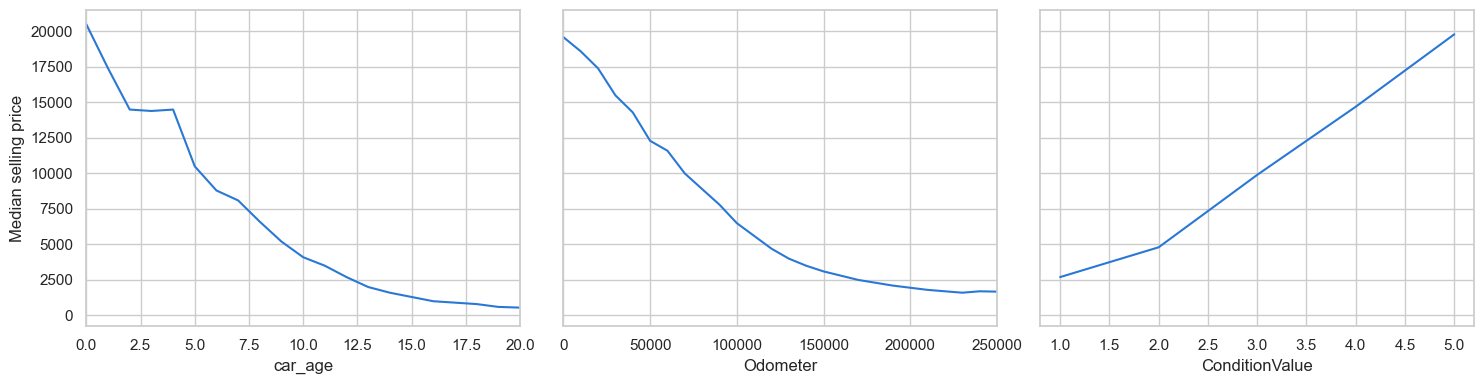

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

sns.lineplot(x=df["car_age"], y=df["SellingPrice"], estimator="median", errorbar=None, color=BLUE, ax=axes[0])
sns.lineplot(x=df["Odometer"] // 10_000 * 10_000, y=df["SellingPrice"], estimator="median", errorbar=None, color=BLUE, ax=axes[1])
sns.lineplot(x=df["ConditionValue"].round(), y=df["SellingPrice"], estimator="median", errorbar=None, color=BLUE, ax=axes[2])

axes[0].set_xlim(0, 20)
axes[1].set_xlim(0, 250_000)
axes[0].set_ylabel("Median selling price")

plt.tight_layout()
plt.show()

### 5. Price by body type

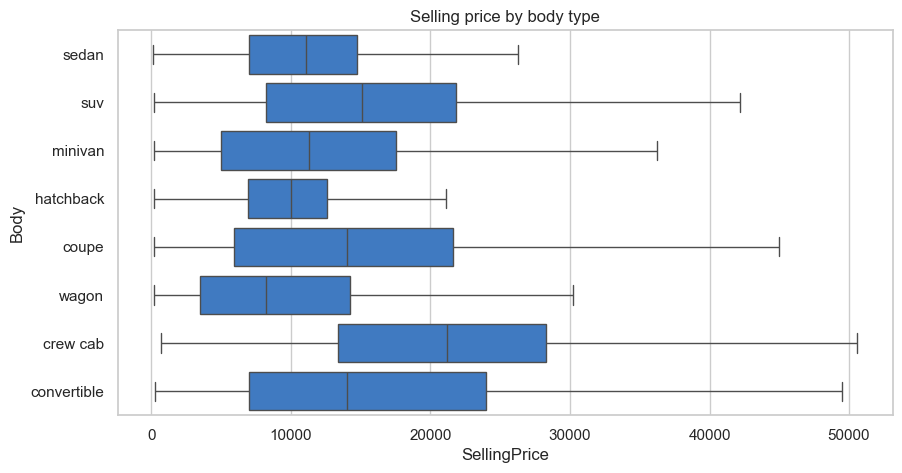

In [21]:
top_bodies = df["Body"].value_counts().index[:8]

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df["Body"].isin(top_bodies)], x="SellingPrice", y="Body", order=top_bodies, color=BLUE, showfliers=False)
plt.title("Selling price by body type")
plt.show()

### 6. Price by make

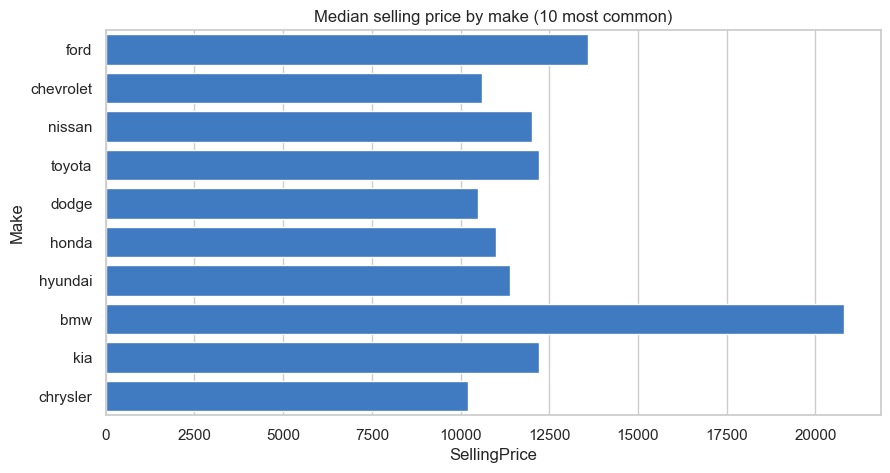

In [22]:
top_makes = df["Make"].value_counts().index[:10]

plt.figure(figsize=(10, 5))
sns.barplot(data=df[df["Make"].isin(top_makes)], x="SellingPrice", y="Make", order=top_makes,
            estimator="median", errorbar=None, color=BLUE)
plt.title("Median selling price by make (10 most common)")
plt.show()

### 7. Selling price vs MMR

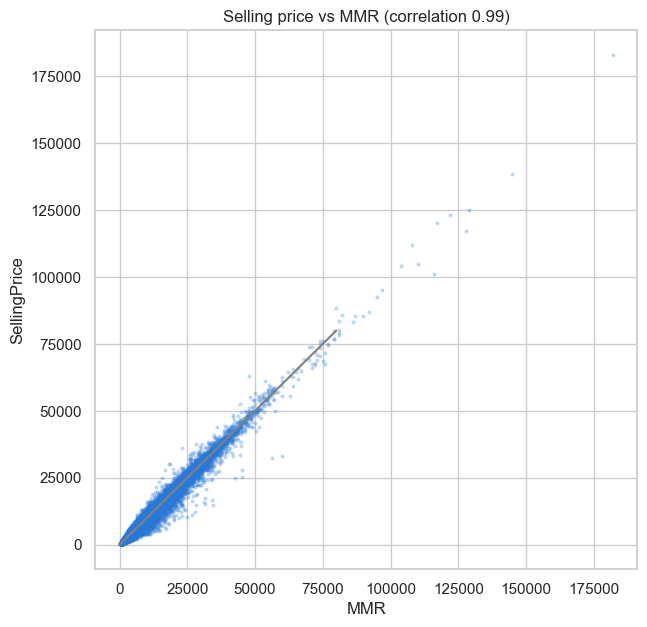

In [23]:
sample = df.sample(20_000, random_state=42)

plt.figure(figsize=(7, 7))
sns.scatterplot(data=sample, x="MMR", y="SellingPrice", s=8, alpha=0.3, color=BLUE, linewidth=0)
plt.plot([0, 80_000], [0, 80_000], color="gray")
plt.title(f"Selling price vs MMR (correlation {df['SellingPrice'].corr(df['MMR']):.2f})")
plt.show()

## C. Multivariate analysis

### 8. Correlation between numeric columns

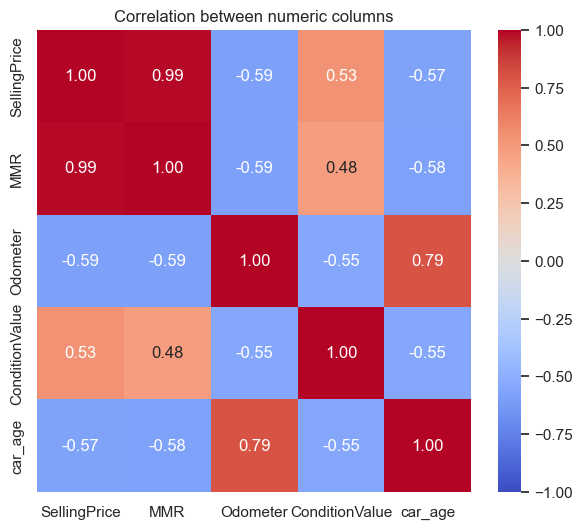

In [24]:
num_cols = ["SellingPrice", "MMR", "Odometer", "ConditionValue", "car_age"]

plt.figure(figsize=(7, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

### 9. Price by age for each body type

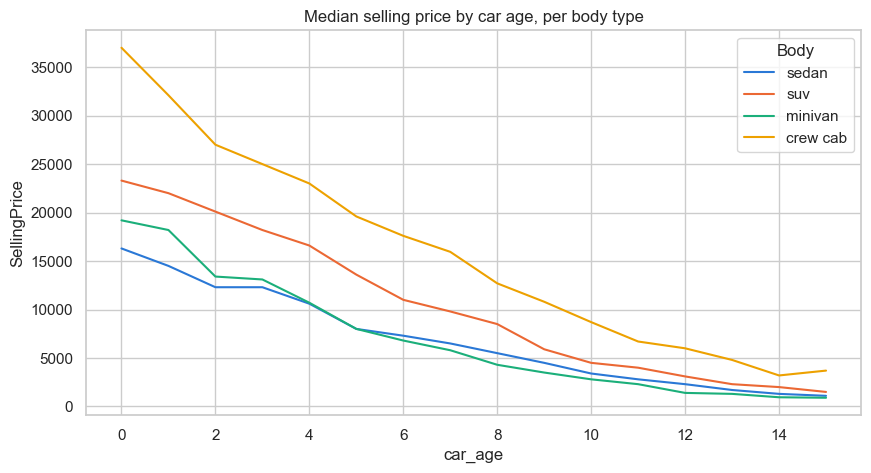

car_age,0,5,10
Body,,,
crew cab,"37,000.00","19,600.00","8,700.00"
minivan,"19,200.00","8,000.00","2,800.00"
sedan,"16,300.00","8,000.00","3,400.00"
suv,"23,300.00","13,600.00","4,500.00"


In [25]:
bodies = ["sedan", "suv", "minivan", "crew cab"]
subset = df[df["Body"].isin(bodies) & (df["car_age"] <= 15)]

plt.figure(figsize=(10, 5))
sns.lineplot(data=subset, x="car_age", y="SellingPrice", hue="Body", hue_order=bodies,
             estimator="median", errorbar=None, palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
plt.title("Median selling price by car age, per body type")
plt.show()

subset.pivot_table(index="Body", columns="car_age", values="SellingPrice", aggfunc="median")[[0, 5, 10]]

### 10. Price by age and condition

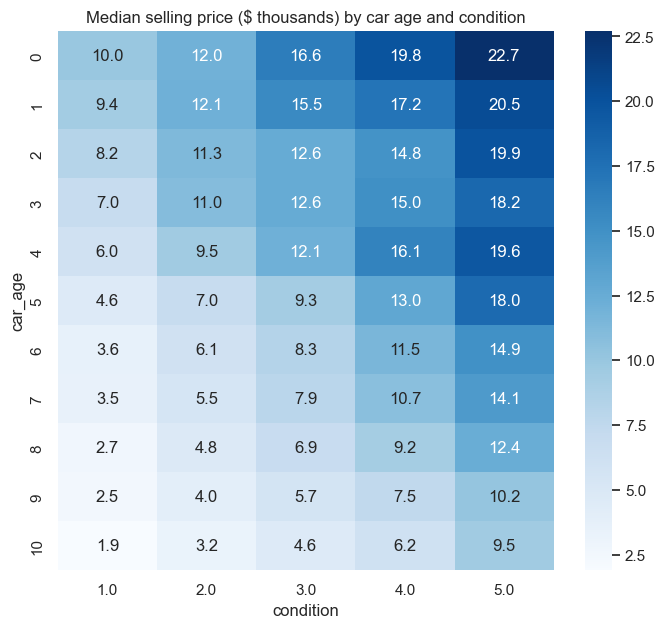

In [26]:
table = (
    df[df["car_age"] <= 10]
    .assign(condition=df["ConditionValue"].round())
    .pivot_table(index="car_age", columns="condition", values="SellingPrice", aggfunc="median")
)

plt.figure(figsize=(8, 7))
sns.heatmap(table / 1000, annot=True, fmt=".1f", cmap="Blues")
plt.title("Median selling price ($ thousands) by car age and condition")
plt.show()

## Key findings

**Univariate**
- A typical car sells for about \$12,300, and most (79%) sell for under \$20,000
- Most cars are young (67% are 5 years old or less) and automatic (96%)
- Ford, Chevrolet and Nissan are the most common makes; sedans and SUVs are the most common bodies

**Bivariate**
- Older cars and cars with more miles sell for less; cars in better condition sell for more
- Crew cabs and SUVs sell for the most, wagons and hatchbacks for the least
- Among the 10 most common makes, BMW sells for the most (about \$20,800); the rest are about \$10,000–13,600
- Selling price is almost equal to MMR (correlation 0.99)

**Multivariate**
- Odometer and car age are strongly linked (0.79), so they tell a similar story
- SUVs and crew cabs keep their value better than sedans and minivans
- Condition matters at every age: a 5-year-old car in condition 5 sells for about 4× one in condition 1 (\$18,000 vs \$4,600)